# 1. Import Libraries and Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv("LCC data.csv")

In [ ]:
data

,Year,Eco Region,State,Areas,No. of sites,Protection Status,LCC%,Unnamed: 7
0,2014,Sunda Shelf,Terengganu,Perhentian,10,Marine Park,53.62,NaN
1,2014,Sunda Shelf,Terengganu,Redang,12,Marine Park,58.13,NaN
2,2014,Sunda Shelf,Pahang,Tioman,19,Marine Park,60.60,NaN
3,2014,Sunda Shelf,Terengganu,Kapas,4,Marine Park,56.88,NaN
4,2014,Sunda Shelf,Terengganu,Bidong/Yu,6,Marine Park,54.58,NaN
...,...,...,...,...,...,...,...,...
376,2025,North Borneo,Sabah,Sipadan,12,Sabah Parks,55.21,NaN
377,2025,North Borneo,Sabah,TARP,8,Sabah Parks,13.13,NaN
378,2025,North Borneo,Sabah,TMP,18,Sabah Parks,40.35,NaN
379,2025,North Borneo,Sabah,TSMP,12,Sabah Parks,51.77,NaN


# 2. Data Cleaning

In [ ]:
def has_repeated_words(text):
    if not isinstance(text, str): # Handle non-string entries if any
        return False
    words = text.lower().split()
    return len(words) != len(set(words))

repeated_words_rows = data[data['Areas'].apply(has_repeated_words)]

if not repeated_words_rows.empty:
    print("Rows with repeated words in the 'Areas' column:")
    print(repeated_words_rows)
else:
    print("No rows found with repeated words in the 'Areas' column.")

Rows with repeated words in the 'Areas' column:
     Year    Eco Region  State    Areas  No. of sites Protection Status  \
73   2016  North Borneo  Sabah  Pom Pom             4     No protection   
134  2018  North Borneo  Sabah  Pom Pom             9     No protection   
159  2019  North Borneo  Sabah  Pom Pom             7     No protection   

      LCC%  Unnamed: 7  
73   18.75         NaN  
134  12.01         NaN  
159  22.77         NaN  


In [ ]:
data['Areas'] = data['Areas'].replace(['Bidong/Yu', 'Bidong and Yu', 'Bidong & Yu'], 'Bidong and Yu')

In [ ]:
data['Areas'] = data['Areas'].replace({
    'Mataking/Pom Pom': 'Mataking',
    'Rawa': 'Pulau Rawa',
    'Sipadan Island': 'Sipadan',
    'Tengah': 'Pulau Tengah',
    'Aur & Dayang': 'Pulau Aur and Dayang',
    'Besar': 'Pulau Besar',
    'Mantahani': 'Mantanani'
    'Southern Semporna', 'Northern Semporna': 'Semporna'
})

In [ ]:
data

,Year,Eco Region,State,Areas,No. of sites,Protection Status,LCC%,Unnamed: 7
0,2014,Sunda Shelf,Terengganu,Perhentian,10,Marine Park,53.62,NaN
1,2014,Sunda Shelf,Terengganu,Redang,12,Marine Park,58.13,NaN
2,2014,Sunda Shelf,Pahang,Tioman,19,Marine Park,60.60,NaN
3,2014,Sunda Shelf,Terengganu,Kapas,4,Marine Park,56.88,NaN
4,2014,Sunda Shelf,Terengganu,Bidong and Yu,6,Marine Park,54.58,NaN
...,...,...,...,...,...,...,...,...
376,2025,North Borneo,Sabah,Sipadan,12,Sabah Parks,55.21,NaN
377,2025,North Borneo,Sabah,TARP,8,Sabah Parks,13.13,NaN
378,2025,North Borneo,Sabah,TMP,18,Sabah Parks,40.35,NaN
379,2025,North Borneo,Sabah,TSMP,12,Sabah Parks,51.77,NaN


In [ ]:
print(len(data['Areas'].unique()))

56


In [ ]:
data['Areas'].unique()

array(['Perhentian', 'Redang', 'Tioman', 'Kapas', 'Bidong and Yu',
       'Tenggol', 'Pemanggil', 'Tinggi', 'Sibu', 'Miri', 'Kuching',
       'Sembilan', 'Pangkor Laut', 'Lankayan', 'Mataking', 'Semporna',
       'Mantanani', 'Usukan Cove', 'Tunku Abdul Rahman Park',
       'Tun Sakaran Marine Park', 'Lahad Datu', 'Sipadan', 'Payar',
       'Mabul', 'Kapalai', 'Pulau Tiga', 'Pulau Penyu', 'Balambangan',
       'Maliangin', 'Berungus', 'Mantani', 'Labuan', 'Pom Pom',
       'Pulau Tengah', 'Pulau Rawa', 'Southern Semporna',
       'Pulau Aur and Dayang', 'Lang Tengah',
       'MantananiSouthern Semporna', 'Pulau Besar', 'TARP', 'TSMP',
       'Pulau Lima', 'Malacca', 'Port Dickson', 'Larapan', 'Rhu', 'Gual',
       'Harimau', 'Hujung', 'Lima', 'Mensirip', 'Mertang', 'Pulau Singa',
       'TMP', 'Seri Buat'], dtype=object)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               381 non-null    int64  
 1   Eco Region         381 non-null    object 
 2   State              381 non-null    object 
 3   Areas              381 non-null    object 
 4   No. of sites       381 non-null    int64  
 5   Protection Status  381 non-null    object 
 6   LCC%               380 non-null    float64
 7   Unnamed: 7         0 non-null      float64
dtypes: float64(2), int64(2), object(4)
memory usage: 23.9+ KB


In [ ]:
data.drop(columns=['Unnamed: 7'], inplace=True)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               381 non-null    int64  
 1   Eco Region         381 non-null    object 
 2   State              381 non-null    object 
 3   Areas              381 non-null    object 
 4   No. of sites       381 non-null    int64  
 5   Protection Status  381 non-null    object 
 6   LCC%               380 non-null    float64
dtypes: float64(1), int64(2), object(4)
memory usage: 21.0+ KB


In [ ]:
data.describe()

,Year,No. of sites,LCC%
count,381.000000,381.000000,380.000000
mean,2020.139108,7.674541,44.470316
std,3.485167,4.203896,13.653507
min,2014.000000,1.000000,7.630000
25%,2017.000000,5.000000,34.402500
50%,2021.000000,6.000000,45.940000
75%,2023.000000,11.000000,54.170000
max,2025.000000,19.000000,88.750000


In [ ]:
data

,Year,Eco Region,State,Areas,No. of sites,Protection Status,LCC%
0,2014,Sunda Shelf,Terengganu,Perhentian,10,Marine Park,53.62
1,2014,Sunda Shelf,Terengganu,Redang,12,Marine Park,58.13
2,2014,Sunda Shelf,Pahang,Tioman,19,Marine Park,60.60
3,2014,Sunda Shelf,Terengganu,Kapas,4,Marine Park,56.88
4,2014,Sunda Shelf,Terengganu,Bidong and Yu,6,Marine Park,54.58
...,...,...,...,...,...,...,...
376,2025,North Borneo,Sabah,Sipadan,12,Sabah Parks,55.21
377,2025,North Borneo,Sabah,TARP,8,Sabah Parks,13.13
378,2025,North Borneo,Sabah,TMP,18,Sabah Parks,40.35
379,2025,North Borneo,Sabah,TSMP,12,Sabah Parks,51.77


In [ ]:
data.isnull().sum()

,0
Year,0
Eco Region,0
State,0
Areas,0
No. of sites,0
Protection Status,0
LCC%,1


In [ ]:
print(data[data['LCC%'].isnull()])

     Year    Eco Region  State     Areas  No. of sites Protection Status  LCC%
151  2019  North Borneo  Sabah  Lankayan            15             SIMCA   NaN


In [ ]:
average_lcc_bor_2019 = data[(data['Eco Region'] == 'North Borneo') & (data['Year'] == 2019)]['LCC%'].mean()
data.loc[(data['Eco Region'] == 'North Borneo') & (data['Year'] == 2019) & (data['LCC%'].isnull()), 'LCC%'] = average_lcc_bor_2019
print(f"Filled missing LCC% with average for North Borneo in 2019: {average_lcc_bor_2019:.2f}")

Filled missing LCC% with average for North Borneo in 2019: 32.89


In [ ]:
data.isnull().sum()

,0
Year,0
Eco Region,0
State,0
Areas,0
No. of sites,0
Protection Status,0
LCC%,0


In [ ]:
data.duplicated().sum()

np.int64(0)

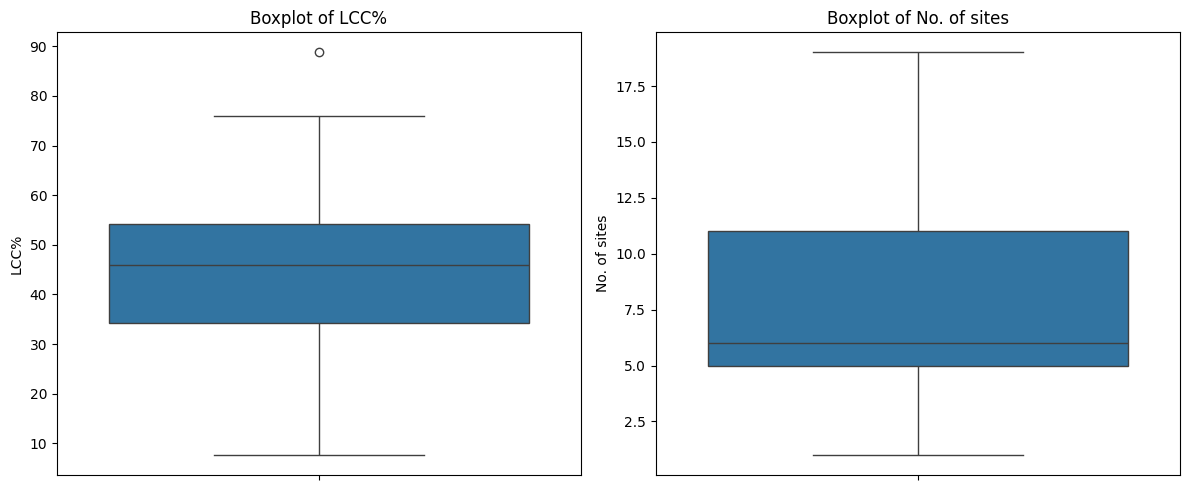

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with two subplots
plt.figure(figsize=(12, 5))

# Boxplot for 'LCC%'
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
sns.boxplot(y=data['LCC%'])
plt.title('Boxplot of LCC%')
plt.ylabel('LCC%')

# Boxplot for 'No. of sites'
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
sns.boxplot(y=data['No. of sites'])
plt.title('Boxplot of No. of sites')
plt.ylabel('No. of sites')

plt.tight_layout()
plt.show()

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               381 non-null    int64  
 1   Eco Region         381 non-null    object 
 2   State              381 non-null    object 
 3   Areas              381 non-null    object 
 4   No. of sites       381 non-null    int64  
 5   Protection Status  381 non-null    object 
 6   LCC%               381 non-null    float64
dtypes: float64(1), int64(2), object(4)
memory usage: 21.0+ KB


## 2.1 EDA

- overall distribution of LCC%

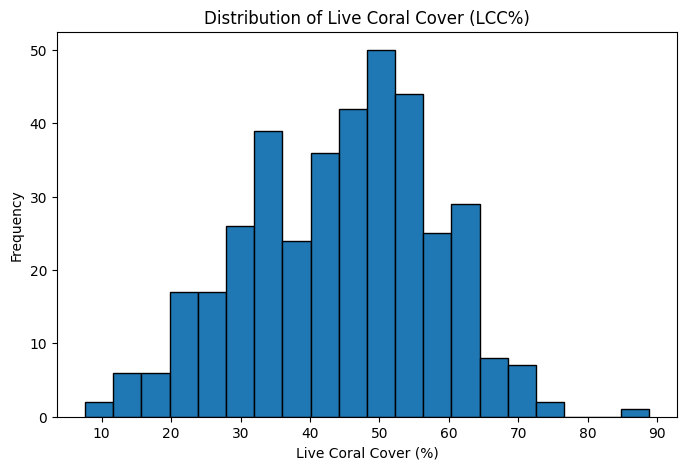

In [ ]:
# Distribution of Live Coral Cover (LCC%)

plt.figure(figsize=(8, 5))

plt.hist(data['LCC%'].dropna(), bins=20, edgecolor='black')

plt.xlabel('Live Coral Cover (%)')
plt.ylabel('Frequency')
plt.title('Distribution of Live Coral Cover (LCC%)')

plt.show()

In [ ]:
data['LCC%'].describe()

,LCC%
count,381.000000
mean,44.439915
std,13.648436
min,7.630000
25%,34.320000
50%,45.940000
75%,54.170000
max,88.750000


- average LCC% by year

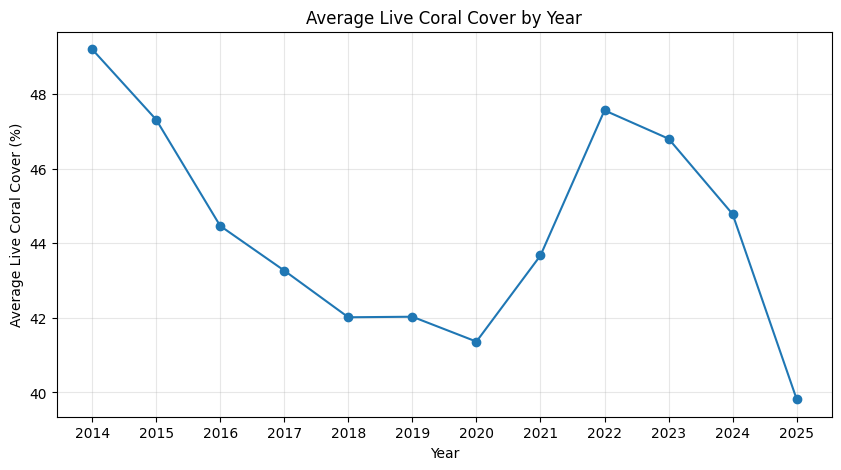

In [ ]:
# Calculate average LCC% for each year
yearly_lcc = data.groupby('Year')['LCC%'].mean().reset_index()

# Plot annual trend
plt.figure(figsize=(10, 5))

plt.plot(yearly_lcc['Year'], yearly_lcc['LCC%'], marker='o')

plt.xlabel('Year')
plt.ylabel('Average Live Coral Cover (%)')
plt.title('Average Live Coral Cover by Year')

plt.xticks(yearly_lcc['Year'])
plt.grid(alpha=0.3)

plt.show()

In [ ]:
yearly_lcc.round(2)

,Year,LCC%
0,2014,49.20
1,2015,47.31
2,2016,44.46
3,2017,43.27
4,2018,42.01
5,2019,42.03
6,2020,41.36
7,2021,43.67
8,2022,47.56
9,2023,46.80


- LCC% across states

<Figure size 1100x600 with 0 Axes>

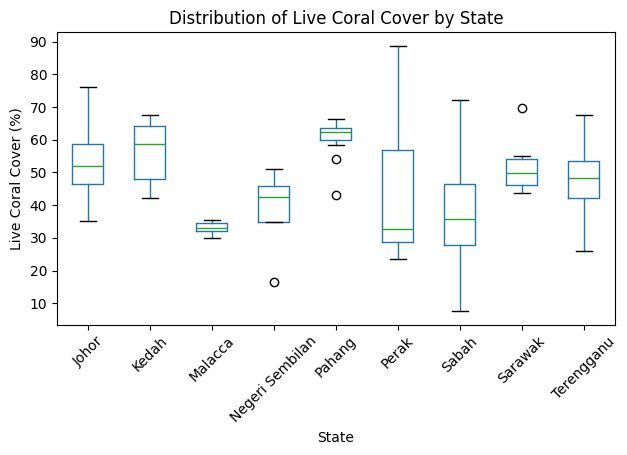

In [ ]:
# Distribution of LCC% by State
plt.figure(figsize=(11, 6))

data.boxplot(
    column='LCC%',
    by='State',
    grid=False,
    rot=45
)

plt.xlabel('State')
plt.ylabel('Live Coral Cover (%)')
plt.title('Distribution of Live Coral Cover by State')
plt.suptitle('')

plt.tight_layout()
plt.show()

In [ ]:
state_lcc = (
    data.groupby('State')['LCC%']
      .agg(['count', 'mean', 'median', 'std'])
      .round(2)
      .sort_values('mean', ascending=False)
)

state_lcc

,count,mean,median,std
State,,,,
Pahang,15,60.56,62.50,5.68
Kedah,8,56.23,58.82,9.61
Johor,87,52.69,52.03,9.11
Sarawak,10,51.27,49.76,7.59
Terengganu,69,47.28,48.28,9.85
Perak,20,43.84,32.86,18.80
Negeri Sembilan,5,38.19,42.50,13.41
Sabah,162,36.92,35.94,12.71
Malacca,5,33.13,33.13,2.15


- LCC% across eco regions

<Figure size 1000x600 with 0 Axes>

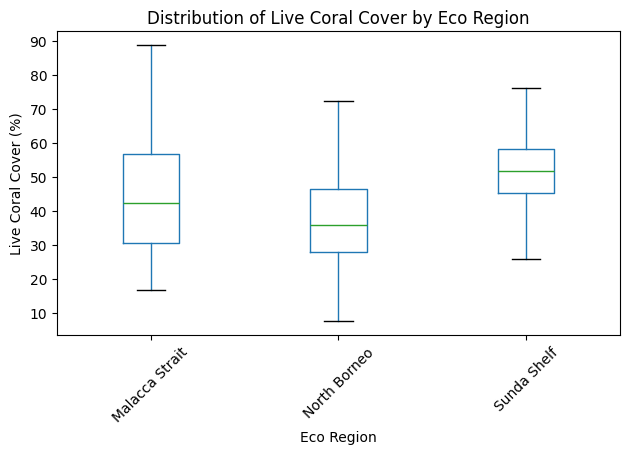

In [ ]:
# Distribution of LCC% by Eco Region
plt.figure(figsize=(10, 6))

data.boxplot(
    column='LCC%',
    by='Eco Region',
    grid=False,
    rot=45
)

plt.xlabel('Eco Region')
plt.ylabel('Live Coral Cover (%)')
plt.title('Distribution of Live Coral Cover by Eco Region')
plt.suptitle('')

plt.tight_layout()
plt.show()

In [ ]:
eco_lcc = (
    data.groupby('Eco Region')['LCC%']
        .agg(['count', 'mean', 'median', 'std'])
        .round(2)
        .sort_values('mean', ascending=False)
)

eco_lcc

,count,mean,median,std
Eco Region,,,,
Sunda Shelf,181,51.20,51.75,9.79
Malacca Strait,38,44.29,42.40,16.48
North Borneo,162,36.92,35.94,12.71


- LCC% by protection status

In [ ]:
data['Protection Status'].value_counts()

,count
Protection Status,
Marine Park,156
No protection,119
Sabah Parks,34
SIMCA,12
"Marine Park, Johor",10
"Marine Park, Terengganu",9
Tun Sakaran Marine Park,5
Sipadan Island Park,5
Turtle Islands Park,4


<Figure size 1000x900 with 0 Axes>

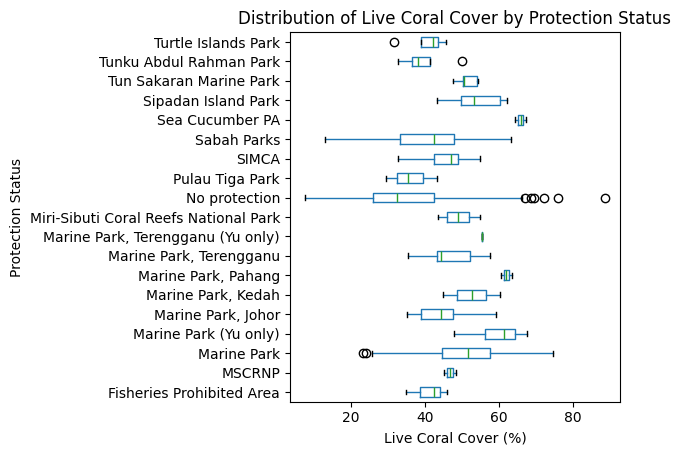

In [ ]:
# Distribution of LCC% by Protection Status
plt.figure(figsize=(10, 9))

data.boxplot(
    column='LCC%',
    by='Protection Status',
    vert=False,
    grid=False
)

plt.xlabel('Live Coral Cover (%)')
plt.ylabel('Protection Status')
plt.title('Distribution of Live Coral Cover by Protection Status')
plt.suptitle('')

plt.tight_layout()
plt.show()

In [ ]:
protection_lcc = (
    data.groupby('Protection Status')['LCC%']
        .agg(['count', 'mean', 'median', 'std'])
        .round(2)
        .sort_values('mean', ascending=False)
)

protection_lcc

,count,mean,median,std
Protection Status,,,,
Sea Cucumber PA,2,65.94,65.94,2.21
"Marine Park, Pahang",2,62.14,62.14,2.18
Marine Park (Yu only),4,59.61,61.40,8.44
"Marine Park, Terengganu (Yu only)",1,55.52,55.52,NaN
Sipadan Island Park,5,53.91,53.33,7.73
"Marine Park, Kedah",2,52.69,52.69,11.05
Tun Sakaran Marine Park,5,51.43,50.68,2.84
Marine Park,156,50.78,51.60,10.12
Miri-Sibuti Coral Reefs National Park,4,49.12,48.96,4.87


- number of cites vs LCC%

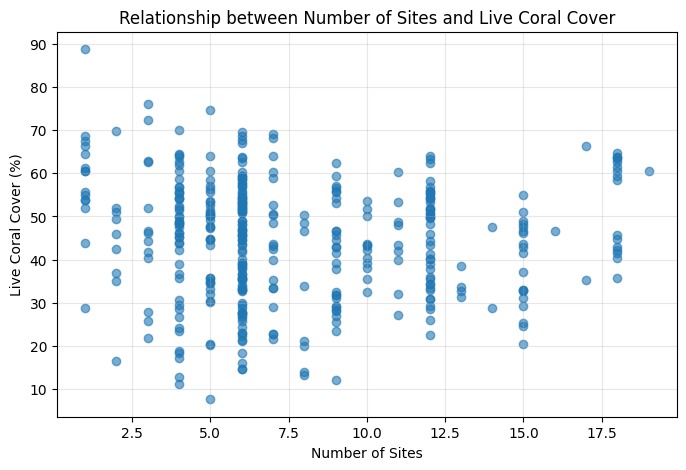

In [ ]:
# Relationship between Number of Sites and LCC%
plt.figure(figsize=(8, 5))

plt.scatter(
    data['No. of sites'],
    data['LCC%'],
    alpha=0.6
)

plt.xlabel('Number of Sites')
plt.ylabel('Live Coral Cover (%)')
plt.title('Relationship between Number of Sites and Live Coral Cover')

plt.grid(alpha=0.3)
plt.show()

In [ ]:
correlation = data['No. of sites'].corr(data['LCC%'])

print(f"Correlation between No. of sites and LCC%: {correlation:.3f}")

Correlation between No. of sites and LCC%: -0.046


# 3. Feature Engineering

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge  # Ridge handles high cardinality better than raw LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

In [ ]:
# 1. Define feature categories
cat_cols = ['Eco Region', 'State', 'Areas', 'Protection Status']
num_cols = ['Year', 'No. of sites']

In [ ]:
X = data[['Year', 'Eco Region', 'State', 'Areas', 'Protection Status', 'No. of sites']]
y = data['LCC%']

# Ensure categorical columns are formatted as strings
for col in cat_cols:
    X[col] = X[col].astype(str)

# 2. Build preprocessor to encode text features
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('num', 'passthrough', num_cols)
    ]
)

/tmp/ipykernel_1344/3846587093.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = X[col].astype(str)
/tmp/ipykernel_1344/3846587093.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = X[col].astype(str)
/tmp/ipykernel_1344/3846587093.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.h

In [ ]:
# 3. Combine preprocessor and regressor into a single Pipeline
model_pipeline = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=10.0))
])

# 4. Data Partitioning

In [ ]:
# 4. Bin target for Stratified K-Fold
y_binned = pd.qcut(y, q=4, labels=False)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
# 5. Run Cross-Validation on the PIPELINE (not raw model)
cv_results = cross_validate(
    model_pipeline, X, y,
    cv=skf.split(X, y_binned),
    scoring=['r2', 'neg_root_mean_squared_error']
)

In [ ]:
print(f"Mean R2 Score: {cv_results['test_r2'].mean():.3f}")
print(f"Mean RMSE: {-cv_results['test_neg_root_mean_squared_error'].mean():.2f}%")

Mean R2 Score: 0.542
Mean RMSE: 9.19%


In [ ]:
data

,Year,Eco Region,State,Areas,No. of sites,Protection Status,LCC%
0,2014,Sunda Shelf,Terengganu,Perhentian,10,Marine Park,53.62
1,2014,Sunda Shelf,Terengganu,Redang,12,Marine Park,58.13
2,2014,Sunda Shelf,Pahang,Tioman,19,Marine Park,60.60
3,2014,Sunda Shelf,Terengganu,Kapas,4,Marine Park,56.88
4,2014,Sunda Shelf,Terengganu,Bidong and Yu,6,Marine Park,54.58
...,...,...,...,...,...,...,...
376,2025,North Borneo,Sabah,Sipadan,12,Sabah Parks,55.21
377,2025,North Borneo,Sabah,TARP,8,Sabah Parks,13.13
378,2025,North Borneo,Sabah,TMP,18,Sabah Parks,40.35
379,2025,North Borneo,Sabah,TSMP,12,Sabah Parks,51.77


# 5. Training Model

# CatBoost Regression

In [ ]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.9 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostRegressor

In [ ]:
# Bin continuous LCC% into 4 quartiles for stratified splitting
y_binned = pd.qcut(y, q=4, labels=False)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
cv_r2, cv_rmse = [], []

In [ ]:
# Perform CV loop
for fold, (train_idx, test_idx) in enumerate(skf.split(X, y_binned), 1):
    X_tr, X_val = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[test_idx]

In [ ]:
cb_fold = CatBoostRegressor(
        iterations=500,
        learning_rate=0.1,
        depth=5,
        cat_features=cat_cols,
        random_seed=85,
        verbose=0,
        l2_leaf_reg=3
    )

In [ ]:
cb_fold.fit(X_tr, y_tr, eval_set=(X_val, y_val), early_stopping_rounds=1000)

CatBoostRegressor(cat_features=['Eco Region', 'State', 'Areas', 'Protection Status'], depth=5, iterations=500, l2_leaf_reg=3, learning_rate=0.1, loss_function='RMSE', random_seed=85, verbose=0)

In [ ]:
preds = cb_fold.predict(X_val)

In [ ]:
from sklearn.metrics import r2_score, root_mean_squared_error

r2 = r2_score(y_val, preds)
rmse = root_mean_squared_error(y_val, preds)

In [ ]:
cv_r2.append(r2)
cv_rmse.append(rmse)
print(f"Fold {fold} - R²: {r2:.3f} | RMSE: {rmse:.2f}%")

Fold 5 - R²: 0.636 | RMSE: 8.67%


In [ ]:
print(f"\n--- CatBoost CV Summary ---")
print(f"Mean R² Score: {np.mean(cv_r2):.3f}")
print(f"Mean RMSE:     {np.mean(cv_rmse):.2f}%")


--- CatBoost CV Summary ---
Mean R² Score: 0.636
Mean RMSE:     8.67%


# Hyperparameter Tuning using GridSearchCV

In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

In [ ]:
from catboost import CatBoostRegressor, Pool

# 1. Create a CatBoost Pool with categorical features defined
train_pool = Pool(X, y, cat_features=cat_cols)

# Define Micro Search Space (12 total fits)
param_grid = {
    'depth': [3, 4, 5, 6],
    'l2_leaf_reg': [3, 6, 10],
    'learning_rate': [0.03, 0.05, 0.07]
}

cb = CatBoostRegressor(
    iterations=300,
    random_seed=42,
    verbose=0
)

# 2. Run native CatBoost grid_search
grid_results = cb.grid_search(
    param_grid,
    X=train_pool,
    cv=list(skf.split(X, y_binned)),
    verbose=False
)

print("Best Parameters:", grid_results['params'])


bestTest = 10.38242923
bestIteration = 264


bestTest = 10.46521657
bestIteration = 180


bestTest = 10.48552431
bestIteration = 55


bestTest = 10.19913512
bestIteration = 261


bestTest = 10.35405118
bestIteration = 258


bestTest = 10.4627808
bestIteration = 128


bestTest = 10.35911606
bestIteration = 299


bestTest = 10.18025269
bestIteration = 154


bestTest = 10.20002477
bestIteration = 181


bestTest = 10.31187776
bestIteration = 299


bestTest = 10.32117419
bestIteration = 214


bestTest = 10.01394889
bestIteration = 115


bestTest = 9.812909708
bestIteration = 269


bestTest = 10.07997039
bestIteration = 166


bestTest = 9.829743164
bestIteration = 114


bestTest = 10.0653452
bestIteration = 299


bestTest = 9.925203103
bestIteration = 232


bestTest = 9.836172816
bestIteration = 148


bestTest = 9.829554437
bestIteration = 237


bestTest = 9.043961076
bestIteration = 286


bestTest = 9.019484977
bestIteration = 146


bestTest = 9.784416231
bestIteration = 285


bestTest = 9

# 6. 1-year Lag Feature To Predict Coming Years (2026 onwards)

In [ ]:
# 1. Sort data chronologically per site
lcc = data.sort_values(by=['Areas', 'Year']).reset_index(drop=True)

In [ ]:
# 2. Engineer 1-Year Lag Feature (LCC_{t-1})
lcc['LCC_Lag1'] = lcc.groupby('Areas')['LCC%'].shift(1)

In [ ]:
# Drop rows missing prior-year baselines (first survey year per site)
lcc_lagged = lcc.dropna(subset=['LCC_Lag1']).copy()

In [ ]:
# 3. Define Updated Feature Set & Target
cat_cols = ['Eco Region', 'State', 'Areas', 'Protection Status']
for col in cat_cols:
    lcc_lagged[col] = lcc_lagged[col].astype(str)

In [ ]:
feature_cols = ['Year', 'Eco Region', 'State', 'Areas', 'Protection Status', 'No. of sites', 'LCC_Lag1']
X = lcc_lagged[feature_cols]
y = lcc_lagged['LCC%']

2025 Temporal Holdout Backtest

In [ ]:
train_mask = lcc_lagged['Year'] < 2025
test_mask = lcc_lagged['Year'] == 2025

In [ ]:
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

In [ ]:
cb_backtest = CatBoostRegressor(
    iterations=500,
    learning_rate=0.1,
    depth=5,
    l2_leaf_reg=3,
    random_seed=67,
    verbose=0
)

In [ ]:
cb_backtest.fit(X_train, y_train, cat_features=cat_cols, early_stopping_rounds=1000)
preds_2025 = cb_backtest.predict(X_test)

In [ ]:
r2_2025 = r2_score(y_test, preds_2025)
rmse_2025 = root_mean_squared_error(y_test, preds_2025)

In [ ]:
from sklearn.metrics import mean_absolute_error

mae_2025 = mean_absolute_error(y_test, preds_2025)

print(f"2025 Unseen R² Score: {r2_2025:.3f}")
print(f"2025 Unseen RMSE:     {rmse_2025:.2f}%")
print(f"2025 Unseen MAE:      {mae_2025:.2f}%\n")

2025 Unseen R² Score: 0.710
2025 Unseen RMSE:     6.78%
2025 Unseen MAE:      5.48%



# 7. Forecasting

In [ ]:
import pandas as pd
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

# 1. Prepare historical data (2014-2025) for comparison
# Start with the original 'data' to maintain its inherent order for years 2014-2025
historical_comparison_base = data[['Year', 'Eco Region', 'State', 'Areas', 'LCC%']].copy()
historical_comparison_base.rename(columns={'LCC%': 'Actual_LCC%'}, inplace=True)
historical_comparison_base['Predicted_LCC%'] = pd.NA # Initialize predicted column

# Get predictions for years 2015-2025 from lcc_lagged (as the model uses LCC_Lag1)
# X_all_years is already defined for 2015-2025 using lcc_lagged
# predicted_lcc_all_years is already defined as predictions for X_all_years
predictions_2015_2025_df = pd.DataFrame({
    'Year': X_all_years['Year'],
    'Eco Region': X_all_years['Eco Region'],
    'State': X_all_years['State'],
    'Areas': X_all_years['Areas'],
    'Predicted_LCC%': predicted_lcc_all_years
})

# Update the historical_comparison_base with predictions for 2015-2025
# We use .loc and index alignment to ensure predictions are placed correctly
for index, row in predictions_2015_2025_df.iterrows():
    mask = (
        (historical_comparison_base['Year'] == row['Year']) &
        (historical_comparison_base['Eco Region'] == row['Eco Region']) &
        (historical_comparison_base['State'] == row['State']) &
        (historical_comparison_base['Areas'] == row['Areas'])
    )
    historical_comparison_base.loc[mask, 'Predicted_LCC%'] = row['Predicted_LCC%']

# 2. Prepare forecasted data for 2026 and 2027
# These DataFrames already exist (lcc_2026, lcc_2027) with 'LCC%_Pred'
forecast_2026_comp = lcc_2026[['Year', 'Eco Region', 'State', 'Areas', 'LCC%_Pred']].copy()
forecast_2026_comp.rename(columns={'LCC%_Pred': 'Predicted_LCC%'}, inplace=True)
forecast_2026_comp['Actual_LCC%'] = pd.NA # No actual LCC% for forecasted years

forecast_2027_comp = lcc_2027[['Year', 'Eco Region', 'State', 'Areas', 'LCC%_Pred']].copy()
forecast_2027_comp.rename(columns={'LCC%_Pred': 'Predicted_LCC%'}, inplace=True)
forecast_2027_comp['Actual_LCC%'] = pd.NA # No actual LCC% for forecasted years

# 3. Concatenate all parts to form the final comparison_df (2014-2027)
comparison_df = pd.concat([historical_comparison_base, forecast_2026_comp, forecast_2027_comp], ignore_index=True)

print("Comparison of Actual and Predicted LCC for all years (2014-2027) - Arranged like full_lcc_data:")
print(comparison_df.round(2))

print("\n--- Evaluation Metrics (2015-2025, where both actual and predicted values are available) ---")

# Filter for years where both actual and predicted values exist (2015-2025)
eval_df = comparison_df.dropna(subset=['Actual_LCC%', 'Predicted_LCC%'])

# Evaluate predictions for applicable years combined
r2_eval = r2_score(eval_df['Actual_LCC%'], eval_df['Predicted_LCC%'])
rmse_eval = root_mean_squared_error(eval_df['Actual_LCC%'], eval_df['Predicted_LCC%'])
mae_eval = mean_absolute_error(eval_df['Actual_LCC%'], eval_df['Predicted_LCC%'])

print(f"Overall R² Score (2015-2025): {r2_eval:.3f}")
print(f"Overall RMSE (2015-2025):     {rmse_eval:.2f}%")
print(f"Overall MAE (2015-2025):      {mae_eval:.2f}%\n")

print("--- Evaluation Metrics by Year (2015-2025) ---")
for year in sorted(eval_df['Year'].unique()):
    year_df = eval_df[eval_df['Year'] == year]
    r2_year = r2_score(year_df['Actual_LCC%'], year_df['Predicted_LCC%'])
    rmse_year = root_mean_squared_error(year_df['Actual_LCC%'], year_df['Predicted_LCC%'])
    mae_year = mean_absolute_error(year_df['Actual_LCC%'], year_df['Predicted_LCC%'])
    print(f"{year} R² Score: {r2_year:.3f}")
    print(f"{year} RMSE:     {rmse_year:.2f}%")
    print(f"{year} MAE:      {mae_year:.2f}%\n")

Comparison of Actual and Predicted LCC for all years (2014-2027) - Arranged like full_lcc_data:
     Year    Eco Region       State          Areas  Actual_LCC% Predicted_LCC%
0    2014   Sunda Shelf  Terengganu     Perhentian        53.62           <NA>
1    2014   Sunda Shelf  Terengganu         Redang        58.13           <NA>
2    2014   Sunda Shelf      Pahang         Tioman        60.60           <NA>
3    2014   Sunda Shelf  Terengganu          Kapas        56.88           <NA>
4    2014   Sunda Shelf  Terengganu  Bidong and Yu        54.58           <NA>
..    ...           ...         ...            ...          ...            ...
456  2027  North Borneo       Sabah           TSMP          NaN      48.639129
457  2027   Sunda Shelf  Terengganu        Tenggol          NaN      48.879357
458  2027   Sunda Shelf       Johor         Tinggi          NaN      53.159061
459  2027   Sunda Shelf      Pahang         Tioman          NaN      49.452454
460  2027  North Borneo       Sabah

/tmp/ipykernel_1344/3601509867.py:43: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  comparison_df = pd.concat([historical_comparison_base, forecast_2026_comp, forecast_2027_comp], ignore_index=True)


In [ ]:
comparison_df.to_csv('comparison_all_years.csv', index=False)

In [ ]:
print(comparison_df.round(2))

            Areas  Year  Actual_LCC%  Predicted_LCC%
0   Bidong and Yu  2024        59.27           60.99
1            Gual  2024        55.76           52.90
2         Harimau  2024        60.27           60.02
3          Hujung  2024        46.60           52.59
4         Kapalai  2024        20.50           22.48
..            ...   ...          ...             ...
76           TSMP  2025        51.77           52.66
77        Tenggol  2025        54.17           52.15
78         Tinggi  2025        52.50           52.86
79         Tioman  2025        42.99           54.49
80    Usukan Cove  2025        15.94           30.80

[81 rows x 4 columns]


In [ ]:
comparison_df.to_csv('comparison_2024_2025_forecast.csv', index=False)

In [ ]:
latest_2025 = lcc[lcc['Year'] == 2025].copy()

2026

In [ ]:
lcc_2026 = latest_2025.copy()
lcc_2026['Year'] = 2026
lcc_2026['LCC_Lag1'] = latest_2025['LCC%'].values

In [ ]:
# Predict 2026
lcc_2026['LCC%_Pred'] = cb_backtest.predict(lcc_2026[feature_cols])

2027

In [ ]:
# 4. Build 2027 Feature Payload (Recursive - Using Predicted 2026 Data as Lag)
lcc_2027 = lcc_2026.copy()
lcc_2027['Year'] = 2027
lcc_2027['LCC_Lag1'] = lcc_2026['LCC%_Pred'].values  # Predicted 2026 LCC% becomes 2027 Lag

In [ ]:
# Predict 2027
lcc_2027['LCC%_Pred'] = cb_backtest.predict(lcc_2027[feature_cols])

Assign LCC Rating Levels (Source: Reef Check Malaysia Bhd)

In [ ]:
def assign_coral_rating(lcc):
    if lcc <= 25.0:
        return 'Poor'
    elif lcc <= 50.0:
        return 'Fair'
    elif lcc <= 75.0:
        return 'Good'
    else:
        return 'Excellent'

In [ ]:
# 5. Updated Processing with 4-Tier Scale
rmse_2026 = 6.78  # From holdout backtest

In [ ]:
# Apply rating to 2026 forecasts
lcc_2026['Coral_Rating'] = lcc_2026['LCC%_Pred'].apply(assign_coral_rating)
lcc_2026['Lower_Bound_95'] = np.clip(lcc_2026['LCC%_Pred'] - rmse_2026, 0, 100)
lcc_2026['Upper_Bound_95'] = np.clip(lcc_2026['LCC%_Pred'] + rmse_2026, 0, 100)

# Apply rating to 2027 forecasts
rmse_2027 = 6.78 * np.sqrt(2)
lcc_2027['Coral_Rating'] = lcc_2027['LCC%_Pred'].apply(assign_coral_rating)
lcc_2027['Lower_Bound_95'] = np.clip(lcc_2027['LCC%_Pred'] - rmse_2027, 0, 100)
lcc_2027['Upper_Bound_95'] = np.clip(lcc_2027['LCC%_Pred'] + rmse_2027, 0, 100)

 Prediction Output

In [ ]:
# Export column selection
export_cols = [
    'Year', 'Eco Region', 'State', 'Areas', 'Protection Status',
    'LCC_Lag1', 'LCC%_Pred', 'Coral_Rating'
]

In [ ]:
forecast_output = pd.concat([lcc_2026[export_cols], lcc_2027[export_cols]], ignore_index=True)
forecast_output

,Year,Eco Region,State,Areas,Protection Status,LCC_Lag1,LCC%_Pred,Coral_Rating
0,2026,Sunda Shelf,Terengganu,Bidong and Yu,Marine Park (Yu only),48.020000,50.718563,Good
1,2026,Sunda Shelf,Johor,Gual,Marine Park,45.310000,50.006118,Good
2,2026,Sunda Shelf,Johor,Harimau,Marine Park,48.960000,49.907105,Fair
3,2026,Sunda Shelf,Johor,Hujung,Marine Park,41.770000,46.649166,Fair
4,2026,North Borneo,Sabah,Kapalai,No protection,14.690000,19.820225,Poor
...,...,...,...,...,...,...,...,...
75,2027,North Borneo,Sabah,TSMP,Sabah Parks,45.909461,48.639129,Fair
76,2027,Sunda Shelf,Terengganu,Tenggol,Marine Park,50.950793,48.879357,Fair
77,2027,Sunda Shelf,Johor,Tinggi,Marine Park,54.135518,53.159061,Good
78,2027,Sunda Shelf,Pahang,Tioman,Marine Park,46.372346,49.452454,Fair


Cleaned Output

In [ ]:
export_cols_cleaned = [
    'Year', 'Eco Region', 'Areas',
    'LCC_Lag1', 'LCC%_Pred', 'Coral_Rating'
]

forecast_output_cleaned = pd.concat([lcc_2026[export_cols_cleaned], lcc_2027[export_cols_cleaned]], ignore_index=True)

forecast_output_cleaned = forecast_output_cleaned.rename(columns={
    'LCC_Lag1': 'LCC 2025',
    'LCC%_Pred': 'Forecasted LCC%'
})

forecast_output_cleaned['LCC 2025'] = forecast_output_cleaned['LCC 2025'].round(1)
forecast_output_cleaned['Forecasted LCC%'] = forecast_output_cleaned['Forecasted LCC%'].round(1)

In [ ]:
print(forecast_output_cleaned.head())

   Year    Eco Region          Areas  LCC 2025  Forecasted LCC% Coral_Rating
0  2026   Sunda Shelf  Bidong and Yu      48.0             50.7         Good
1  2026   Sunda Shelf           Gual      45.3             50.0         Good
2  2026   Sunda Shelf        Harimau      49.0             49.9         Fair
3  2026   Sunda Shelf         Hujung      41.8             46.6         Fair
4  2026  North Borneo        Kapalai      14.7             19.8         Poor


In [ ]:
print(forecast_output_cleaned.tail())

    Year    Eco Region        Areas  LCC 2025  Forecasted LCC% Coral_Rating
75  2027  North Borneo         TSMP      45.9             48.6         Fair
76  2027   Sunda Shelf      Tenggol      51.0             48.9         Fair
77  2027   Sunda Shelf       Tinggi      54.1             53.2         Good
78  2027   Sunda Shelf       Tioman      46.4             49.5         Fair
79  2027  North Borneo  Usukan Cove      20.6             23.4         Poor


Percentage of live coral cover Rating:

0-25 Poor

26-50 Fair

51-75 Good

76-100 Excellent

Source: Reef Check Malaysia Bhd



In [ ]:
# 1. Prepare historical data (up to 2025)
historical_data = data.copy()
historical_data['LCC_Actual_or_Predicted'] = historical_data['LCC%']
historical_data['Coral_Rating'] = historical_data['LCC%'].apply(assign_coral_rating)

# 2. Prepare forecasted data for 2026 and 2027
# lcc_2026 and lcc_2027 already have LCC%_Pred and Coral_Rating
# Select common columns and rename LCC%_Pred to match historical_data
forecast_2026 = lcc_2026[[    'Year', 'Eco Region', 'State', 'Areas', 'No. of sites', 'Protection Status', 'LCC%_Pred', 'Coral_Rating']].copy()
forecast_2026.rename(columns={'LCC%_Pred': 'LCC_Actual_or_Predicted'}, inplace=True)

forecast_2027 = lcc_2027[[    'Year', 'Eco Region', 'State', 'Areas', 'No. of sites', 'Protection Status', 'LCC%_Pred', 'Coral_Rating']].copy()
forecast_2027.rename(columns={'LCC%_Pred': 'LCC_Actual_or_Predicted'}, inplace=True)

# 3. Concatenate all dataframes
full_lcc_data = pd.concat([historical_data, forecast_2026, forecast_2027], ignore_index=True)

# Display the first few rows and info of the combined DataFrame
print("Full LCC Data (2014-2027) Head:")
print(full_lcc_data.head())
print("\nFull LCC Data (2014-2027) Tail:")
print(full_lcc_data.tail())
print("\nFull LCC Data Info:")
full_lcc_data.info()

Full LCC Data (2014-2027) Head:
   Year   Eco Region       State          Areas  No. of sites  \
0  2014  Sunda Shelf  Terengganu     Perhentian            10   
1  2014  Sunda Shelf  Terengganu         Redang            12   
2  2014  Sunda Shelf      Pahang         Tioman            19   
3  2014  Sunda Shelf  Terengganu          Kapas             4   
4  2014  Sunda Shelf  Terengganu  Bidong and Yu             6   

  Protection Status   LCC%  LCC_Actual_or_Predicted Coral_Rating  
0       Marine Park  53.62                    53.62         Good  
1       Marine Park  58.13                    58.13         Good  
2       Marine Park  60.60                    60.60         Good  
3       Marine Park  56.88                    56.88         Good  
4       Marine Park  54.58                    54.58         Good  

Full LCC Data (2014-2027) Tail:
     Year    Eco Region       State        Areas  No. of sites  \
456  2027  North Borneo       Sabah         TSMP            12   
457  2027 

In [ ]:
full_lcc_data.to_csv('full_lcc_data.csv', index=False)

/tmp/ipykernel_1344/3751475370.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(


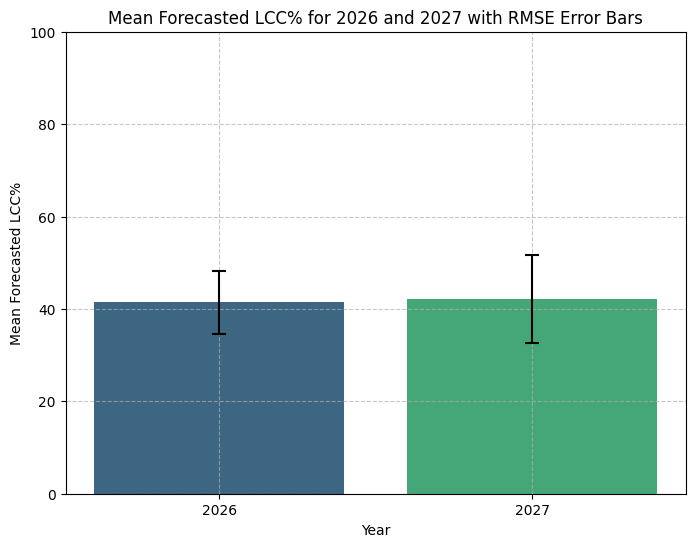

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Calculate mean forecasts
mean_lcc_2026 = lcc_2026['LCC%_Pred'].mean()
mean_lcc_2027 = lcc_2027['LCC%_Pred'].mean()

# Create a DataFrame for plotting
forecast_summary = pd.DataFrame({
    'Year': [2026, 2027],
    'Mean_LCC_Pred': [mean_lcc_2026, mean_lcc_2027],
    'RMSE': [rmse_2026, rmse_2027] # Use RMSE directly for error bars
})

plt.figure(figsize=(8, 6))
barplot = sns.barplot(
    data=forecast_summary,
    x='Year',
    y='Mean_LCC_Pred',
    palette='viridis',
    capsize=0.1
)

# Add error bars based on RMSE
for index, row in forecast_summary.iterrows():
    plt.errorbar(
        x=index, # Barplot x-axis values are 0, 1 for categories
        y=row['Mean_LCC_Pred'],
        yerr=row['RMSE'], # Symmetric error
        color='black',
        capsize=5,
        elinewidth=1.5,
        markeredgewidth=1.5
    )

plt.title('Mean Forecasted LCC% for 2026 and 2027 with RMSE Error Bars')
plt.xlabel('Year')
plt.ylabel('Mean Forecasted LCC%')
plt.ylim(0, 100) # LCC% is between 0 and 100
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Visualise Feature Importance

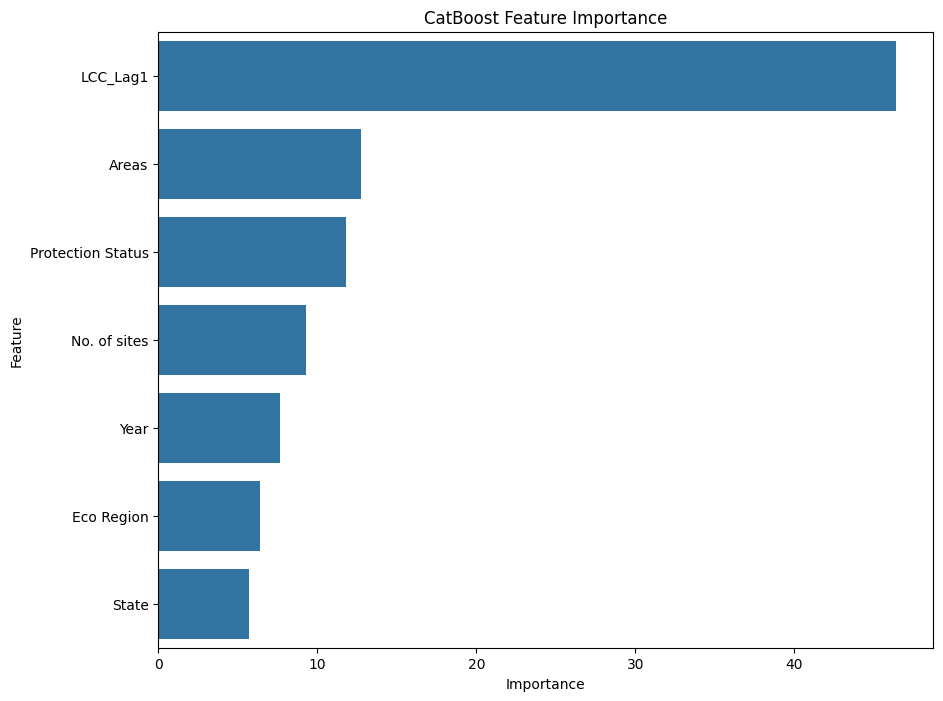

In [ ]:
feature_importances = cb_backtest.get_feature_importance(Pool(X_train, y_train, cat_features=cat_cols))
feature_names = X_train.columns

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('CatBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [ ]:
importance_df.to_csv('feature_importance.csv', index=False)